# Детекция фишинговых URL: постановка задачи, метрика и EDA (PhiUSIIL)

Домашнее задание №1 курса «Программные инструменты анализа данных в задачах ИБ».

**Содержание**
1. Постановка задачи
2. Метрика качества
3. Загрузка данных и описание признаков
4. Базовые статистики
5. Качество данных
6. Целевая переменная
7. Артефакты сборки датасета и утечки
8. Числовые признаки
9. Домен верхнего уровня (TLD)
10. Выбросы
11. Корреляции
12. PCA: насколько классы разделимы
13. Итоговые выводы

## 1. Постановка задачи

### 1.1. Бизнес-постановка

Фишинг остаётся самым массовым вектором первичного проникновения в компанию: сотрудник получает
письмо или сообщение со ссылкой на поддельную страницу входа (почта, банк, Microsoft 365, маркетплейс)
и вводит там свои учётные данные.

Классическая защита - блок-листы (PhishTank, OpenPhish и т.п.) - отстаёт: фишинговая страница живёт
от нескольких часов до пары дней, и к моменту попадания в список рассылка уже прошла.

**Задача:** встроить в почтовый шлюз и веб-прокси компании модуль, который по ссылке (URL) и содержимому
открываемой страницы оценивает вероятность того, что это фишинг, и в зависимости от оценки:
1) блокирует переход (высокая уверенность);
2) показывает пользователю предупреждение и отправляет ссылку на разбор в SOC/песочницу (средняя уверенность);
3) пропускает ссылку (низкая оценка).

Цена ошибок разная:
- **пропуск фишинга (FN)** - компрометация учётной записи, дальше возможны BEC-мошенничество, утечка, вымогатель;
- **ложная блокировка (FP)** - сотрудник не может открыть рабочий сайт, пишет в поддержку; при большом
  числе ложных блокировок пользователи начинают игнорировать предупреждения, а администраторы - добавлять
  исключения, и защита теряет смысл.

### 1.2. Постановка ML-задачи

**Бинарная классификация** (обучение с учителем):
- объект - URL вместе с HTML-страницей, на которую он ведёт;
- целевая переменная - `is_phishing` (1 - фишинг, 0 - легитимный сайт). В исходном файле метка `label`
  закодирована наоборот (1 - легитимный), поэтому вводим инвертированный столбец;
- признаки - 50 числовых признаков URL и HTML-страницы, категориальный признак `TLD`, а также сырые
  `URL` и `Title`, из которых можно строить дополнительные (текстовые) признаки;
- выход модели - вероятность фишинга, порог выбирается под допустимое число ложных блокировок (п. 2).

### 1.3. Набор данных

**PhiUSIIL Phishing URL Dataset** - UCI Machine Learning Repository, id 967
(https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset).
Статья авторов: A. Prasad, S. Chandra. *PhiUSIIL: A diverse security profile empowered phishing URL detection
framework based on similarity index and incremental learning* // Computers & Security, 2024, vol. 136, 103545.

- 235 795 URL: 134 850 легитимных и 100 945 фишинговых;
- 56 столбцов: 54 признака (4 текстовых/категориальных - `URL`, `Domain`, `TLD`, `Title` - и 50 числовых),
  служебное имя файла с HTML-кодом (`FILENAME`) и метка `label`;
- легитимные URL - главные страницы популярных доменов, фишинговые - из открытых фидов фишинга.

Объём выборки (сотни тысяч объектов обоих классов) и набор признаков, описывающих как саму ссылку, так и
содержимое страницы, достаточны для обучения и честной проверки классификатора. Ограничения данных,
найденные в ходе EDA (утечки, артефакты сбора), разобраны в разделах 5 и 7.

## 2. Метрика качества

**Основная метрика: PR-AUC (Average Precision) по классу «фишинг».**

**Обоснование.** Ошибки неравноценны, а в реальном потоке ссылок фишинга - доли процента, поэтому accuracy
и даже ROC-AUC будут выглядеть отлично и при большом числе ложных блокировок; PR-AUC оценивает качество
ранжирования именно для искомого класса, напрямую учитывает ложные срабатывания (через precision) и не
привязана к конкретному порогу, который в продукте будет настраиваться под допустимую нагрузку.

**Рабочая метрика для выбора порога: Recall при FPR ≤ 0.1%** - какую долю фишинга модель ловит,
если ложно блокируется не более 1 легитимной ссылки из 1000. FPR, в отличие от precision, не зависит
от доли фишинга в выборке, поэтому его можно напрямую перенести на реальный поток писем.

Дополнительно будем смотреть матрицу ошибок, F2-score (полнота важнее точности, но не абсолютно)
и MCC - сбалансированную метрику, учитывающую все четыре ячейки матрицы ошибок.

**Почему не accuracy.** В датасете 43% фишинга, а в реальной почте - доли процента. Модель «всё легитимно»
на реальном потоке даст accuracy > 99% и нулевую пользу. Кроме того, как показано в разделе 7.3,
на этом датасете даже правило из одного условия даёт accuracy 99.7% - метрика ничего не различает.

Важно: precision, посчитанная на этом датасете, будет **завышена** относительно продакшена, так как фишинга
здесь искусственно много. Для оценки реальной precision её нужно пересчитать через FPR и ожидаемую долю
фишинга в потоке. То же относится и к самой PR-AUC: она зависит от доли положительного класса (здесь 43%),
поэтому её значения сравниваем только между моделями на одной и той же выборке, а на реальный поток
переносим FPR и Recall.

## 3. Загрузка данных и описание признаков

Для работы с таблицами используются `pandas` и `numpy`, для визуализаций - `matplotlib` и `seaborn`,
для оценки нелинейных связей - `phik`, для проекции на плоскость - `PCA` из `scikit-learn`.

**Данные** в репозиторий не входят (около 57 МБ). Перед запуском скачайте архив с
[UCI](https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset) и положите файл в
`data/PhiUSIIL_Phishing_URL_Dataset.csv` рядом с ноутбуком.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import phik  # noqa: F401 - регистрирует метод DataFrame.phik_matrix
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
PALETTE = {"Легитимный": "#3a7bd5", "Фишинг": "#e4572e"}
ORDER = ["Легитимный", "Фишинг"]

# utf-8-sig: в начале файла стоит BOM, без него первый столбец называется '﻿FILENAME'
df = pd.read_csv("data/PhiUSIIL_Phishing_URL_Dataset.csv", encoding="utf-8-sig")
print(f"Размер датасета: {df.shape[0]:,} строк, {df.shape[1]} столбцов")
display(df.head())

Размер датасета: 235,795 строк, 56 столбцов


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.000,1.000,0.523,0.062,3,1,0,0,0.000,18,0.581,0,0.000,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000,0.000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.000,0.667,0.033,0.050,2,1,0,0,0.000,9,0.391,0,0.000,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.556,55.556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.000,0.867,0.029,0.064,2,2,0,0,0.000,15,0.517,0,0.000,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.667,46.667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.000,1.000,0.523,0.058,3,1,0,0,0.000,13,0.500,0,0.000,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000,0.000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.000,1.000,0.080,0.059,3,1,0,0,0.000,20,0.606,0,0.000,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000,100.000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


**Описание признаков** (по статье авторов датасета и по содержимому столбцов):

*Служебные и целевые:*
1) `FILENAME` - имя файла с сохранённым HTML-кодом страницы (служебный, в признаки не входит);
2) `label` - исходная метка (1 - легитимный, 0 - фишинг); вместо неё используем `is_phishing = 1 - label`.

*Признаки URL:*

3) `URL`, `Domain`, `TLD` - сама ссылка, домен и домен верхнего уровня (текст / категория);
4) `URLLength`, `DomainLength`, `TLDLength` - длины URL, домена и TLD;
5) `IsDomainIP` - вместо домена указан IP-адрес;
6) `NoOfSubDomain` - число поддоменов;
7) `URLSimilarityIndex` - мера сходства URL с эталонным списком легитимных URL (0-100), признак, предложенный авторами;
8) `CharContinuationRate` - доля самых длинных последовательностей одного типа символов (буквы/цифры/спецсимволы);
9) `TLDLegitimateProb` - «вероятность легитимности» TLD по внешнему рейтингу доменов;
10) `URLCharProb` - средняя вероятность символов URL по частотам в легитимных URL;
11) `HasObfuscation`, `NoOfObfuscatedChar`, `ObfuscationRatio` - обфускация (%-кодирование и т.п.);
12) `NoOfLettersInURL` / `LetterRatioInURL`, `NoOfDegitsInURL` / `DegitRatioInURL`,
    `NoOfEqualsInURL`, `NoOfQMarkInURL`, `NoOfAmpersandInURL`, `NoOfOtherSpecialCharsInURL` / `SpacialCharRatioInURL` -
    количество и доля разных типов символов;
13) `IsHTTPS` - схема https.

*Признаки HTML-страницы:*

14) `LineOfCode`, `LargestLineLength` - число строк HTML-кода и длина самой длинной строки;
15) `HasTitle`, `Title`, `DomainTitleMatchScore`, `URLTitleMatchScore` - наличие заголовка, сам заголовок и
    степень совпадения заголовка с доменом / URL;
16) `HasFavicon`, `Robots` (есть robots.txt), `IsResponsive` (адаптивная вёрстка), `HasDescription` (meta description),
    `HasCopyrightInfo`, `HasSocialNet` (ссылки на соцсети);
17) `NoOfURLRedirect`, `NoOfSelfRedirect`, `NoOfPopup`, `NoOfiFrame` - редиректы, всплывающие окна, фреймы;
18) `HasExternalFormSubmit`, `HasSubmitButton`, `HasHiddenFields`, `HasPasswordField` - формы ввода;
19) `Bank`, `Pay`, `Crypto` - упоминания банковской, платёжной и криптовалютной тематики;
20) `NoOfImage`, `NoOfCSS`, `NoOfJS`, `NoOfSelfRef`, `NoOfEmptyRef`, `NoOfExternalRef` - число изображений,
    стилей, скриптов и ссылок (на свой домен, пустых, внешних).

In [2]:
# В исходных данных label = 1 означает ЛЕГИТИМНЫЙ сайт, 0 - фишинговый.
# Для задачи детекции удобнее, чтобы положительным (искомым) классом был фишинг.
df["is_phishing"] = 1 - df["label"]
df["Класс"] = df["is_phishing"].map({0: "Легитимный", 1: "Фишинг"})
TARGET = "is_phishing"

# Разбиение столбцов на группы
service_cols = ["FILENAME", "label", "is_phishing", "Класс"]
text_cols = ["URL", "Domain", "TLD", "Title"]
num_cols = [c for c in df.select_dtypes(include="number").columns if c not in service_cols]
binary_cols = [c for c in num_cols if df[c].nunique() == 2]
cont_cols = [c for c in num_cols if c not in binary_cols]

print("Текстовые/категориальные:", text_cols)
print(f"Числовых признаков: {len(num_cols)}, из них бинарных: {len(binary_cols)}, остальных: {len(cont_cols)}")

Текстовые/категориальные: ['URL', 'Domain', 'TLD', 'Title']
Числовых признаков: 50, из них бинарных: 19, остальных: 31


In [3]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 58 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

1) 235 795 строк, 56 исходных столбцов - 54 признака, `FILENAME` и `label` (+ 2 добавленных нами: `is_phishing` и `Класс` для подписей);
2) 50 числовых признаков: 19 бинарных (0/1) и 31 количественный; 4 текстовых столбца + `FILENAME`;
3) Явных пропусков (NaN) нет ни в одном столбце, но это не значит, что пропусков нет совсем - см. п. 5.1;
4) Признаки делятся на две природно разные группы: **признаки URL** (доступны мгновенно, без обращения к сайту)
   и **признаки HTML** (требуют скачать страницу). Это важно для продукта: в почтовом шлюзе страницу не всегда
   можно загрузить (сайт уже удалён, требует JS, отдаёт разный контент разным клиентам).

## 4. Базовые статистики

`describe()` для количественных признаков: среднее, стандартное отклонение, минимум/максимум и перцентили
(добавлен 99-й, чтобы видеть хвосты). Для текстовых столбцов - число уникальных значений и самое частое.

In [4]:
display(df[cont_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T)

,count,mean,std,min,25%,50%,75%,99%,max
URLLength,"235,795.000",34.573,41.314,13.000,23.000,27.000,34.000,144.000,"6,097.000"
DomainLength,"235,795.000",21.470,9.151,4.000,16.000,20.000,24.000,57.000,110.000
URLSimilarityIndex,"235,795.000",78.431,28.976,0.156,57.025,100.000,100.000,100.000,100.000
CharContinuationRate,"235,795.000",0.846,0.217,0.000,0.680,1.000,1.000,1.000,1.000
TLDLegitimateProb,"235,795.000",0.260,0.252,0.000,0.006,0.080,0.523,0.523,0.523
URLCharProb,"235,795.000",0.056,0.011,0.001,0.051,0.058,0.063,0.074,0.091
TLDLength,"235,795.000",2.764,0.600,2.000,2.000,3.000,3.000,4.000,13.000
NoOfSubDomain,"235,795.000",1.165,0.601,0.000,1.000,1.000,1.000,3.000,10.000
NoOfObfuscatedChar,"235,795.000",0.025,1.876,0.000,0.000,0.000,0.000,0.000,447.000
ObfuscationRatio,"235,795.000",0.000,0.004,0.000,0.000,0.000,0.000,0.000,0.348


1) Шкалы признаков отличаются на порядки: доли (`LetterRatioInURL`, `URLCharProb`) - от 0 до 1,
   `URLLength` - до 6 097 символов, `LineOfCode` - до 442 666 строк, `LargestLineLength` - до 14 млн символов.
   Для линейных моделей и kNN нужна нормализация;
2) У «счётных» признаков среднее намного больше медианы: медиана `LineOfCode` - 429 строк, среднее - 1 142
   при std 3 420; у `URLLength` медиана 27, а максимум 6 097. Распределения сильно скошены вправо (п. 8.1);
3) У многих признаков (`NoOfEqualsInURL`, `NoOfQMarkInURL`, `NoOfObfuscatedChar`, `NoOfPopup`) даже 75-й перцентиль
   равен нулю - признак отличен от нуля у малой доли URL;
4) `URLSimilarityIndex` - медиана и 75-й перцентиль ровно 100: больше половины выборки имеет максимальное значение.
   Ниже (п. 7.3) выясним, что это ровно все легитимные URL;
5) `TLDLegitimateProb` принимает ограниченный набор значений с максимумом 0.523 - это фактически закодированный TLD
   (у `com` - 0.523).

In [5]:
display(df[text_cols + ["FILENAME"]].describe().T)

# Бинарные признаки: доля единиц
display(df[binary_cols].mean().sort_values().to_frame("Доля значений 1").T)

,count,unique,top,freq
URL,235795,235370,https://att-104164.weeblysite.com/,2
Domain,235795,220086,ipfs.io,1197
TLD,235795,695,com,112554
Title,235795,197874,0,32719
FILENAME,235795,235795,521848.txt,1


,HasObfuscation,IsDomainIP,Crypto,NoOfSelfRedirect,HasExternalFormSubmit,HasPasswordField,Bank,NoOfURLRedirect,Pay,Robots,HasFavicon,HasHiddenFields,HasSubmitButton,HasDescription,HasSocialNet,HasCopyrightInfo,IsResponsive,IsHTTPS,HasTitle
Доля значений 1,0.002,0.003,0.023,0.040,0.044,0.102,0.127,0.133,0.237,0.267,0.362,0.378,0.414,0.440,0.457,0.487,0.625,0.783,0.861


1) `URL` почти уникален (235 370 уникальных из 235 795), то есть есть повторы - разберём в п. 5.1;
2) `Domain`: 220 086 уникальных значений, самый частый - `ipfs.io` (1 197 раз). IPFS-шлюзы - популярный
   у фишеров бесплатный хостинг, с которого страницу сложно удалить;
3) `TLD` - 695 уникальных значений, `com` - почти половина выборки; для кодирования понадобится группировка редких TLD (п. 9);
4) Самое частое значение `Title` - строка `'0'` (32 719 раз): это не заголовок, а закодированное «заголовка нет»;
5) Бинарные признаки сильно разбалансированы: `HasObfuscation` и `IsDomainIP` равны 1 лишь у 0.2-0.3% URL,
   а `HasTitle` - у 86%. Редкие флаги могут быть полезны как сильные индикаторы, но статистически ненадёжны.

## 5. Качество данных

### 5.1. Пропуски и дубликаты

Проверяем явные и скрытые пропуски, полные повторы строк, повторы URL и противоречивые записи
(одинаковые признаки - разная метка).

In [6]:
print("Пропусков (NaN) всего:", df.isna().sum().sum())

# Скрытые пропуски: Title = '0' у страниц без заголовка
title_zero = df["Title"].astype(str).eq("0")
print(f"Title == '0': {title_zero.sum():,} строк")
display(pd.crosstab(title_zero, df["Класс"], margins=True).rename(index={False: "Title есть", True: "Title = '0'"}))
print("HasTitle = 0 у строк с Title = '0':", (df.loc[title_zero, "HasTitle"] == 0).mean().round(3))

# Дубликаты
feature_cols = [c for c in df.columns if c not in ("FILENAME",)]
print(f"\nПолных дублей (без FILENAME): {df[feature_cols].duplicated().sum():,}")
dup_url = df["URL"].duplicated(keep=False)
print(f"Строк с повторяющимся URL: {dup_url.sum():,} ({df.loc[dup_url, 'URL'].nunique():,} уникальных URL)")
print("URL с разными метками:", (df[dup_url].groupby("URL")[TARGET].nunique() > 1).sum())
print("Классы среди повторов URL:", df.loc[dup_url, "Класс"].value_counts().to_dict())

# Одинаковые признаки (без URL и служебных столбцов), но разная метка
X_only = [c for c in num_cols + ["TLD"]]
n_lab = df.groupby(X_only)[TARGET].transform("nunique")
print("Строк с одинаковыми числовыми признаками и разной меткой:", (n_lab > 1).sum())

Пропусков (NaN) всего: 0
Title == '0': 32,719 строк


Класс,Легитимный,Фишинг,All
Title,,,
Title есть,134677,68399,203076
Title = '0',173,32546,32719
All,134850,100945,235795


HasTitle = 0 у строк с Title = '0': 1.0



Полных дублей (без FILENAME): 0
Строк с повторяющимся URL: 850 (425 уникальных URL)
URL с разными метками: 0
Классы среди повторов URL: {'Фишинг': 850}


Строк с одинаковыми числовыми признаками и разной меткой: 0


1) Явных пропусков нет, но **`Title = '0'` - скрытый пропуск** (32 719 строк, совпадает с `HasTitle = 0`).
   99.5% таких строк - фишинг. При построении текстовых признаков из `Title` значение `'0'` нужно превратить
   в пустую строку, иначе модель выучит «заголовок '0' = фишинг» как токен. Кроме того, в `Title` встречаются
   артефакты кодировки (`universitÃ¤t` - UTF-8, прочитанный как cp1252) и значения вида `#NAME?` - следы
   обработки в Excel;
2) Полных дубликатов нет, но 425 URL встречаются дважды (850 строк, все - фишинг). У повторов разные `FILENAME`
   и разные HTML-признаки: одну и ту же ссылку прислали два фида и страница скачивалась в разное время.
   Противоречивых меток нет;
3) Повторы URL нужно держать в одной части выборки при разбиении (группировка по URL, например
   `StratifiedGroupKFold` из `scikit-learn`), иначе модель на
   валидации будет «узнавать» знакомые ссылки, и качество окажется завышенным.

### 5.2. Служебный столбец `FILENAME`

Имя файла не должно нести информации о классе. Проверим это.

In [7]:
# Имя файла с HTML-кодом страницы - служебная информация. Проверим, не выдаёт ли она метку.
fname_prefix = df["FILENAME"].str.extract(r"^([A-Za-z]*)")[0].replace("", "цифры")
display(pd.crosstab(fname_prefix, df["Класс"]).rename_axis("Префикс FILENAME"))

fname_num = df["FILENAME"].str.extract(r"(\d+)")[0].astype(float)
display(fname_num.groupby(df["Класс"]).describe()[["min", "50%", "max"]].rename_axis("Номер в FILENAME"))

Класс,Легитимный,Фишинг
Префикс FILENAME,,
m,0,381
mw,0,36286
op,0,589
oph,0,8478
цифры,134850,55211


,min,50%,max
Номер в FILENAME,,,
Легитимный,9.000,"484,217.000","904,971.000"
Фишинг,1.000,"7,960,087.000","8,139,518.000"


**`FILENAME` полностью выдаёт метку:**
1) Префиксы `mw`, `oph`, `op`, `m` (45 734 строки) встречаются только у фишинга - по всей видимости, это
   источник (фиды MalwareWorld, OpenPhish и т.п.);
2) У чисел в имени файла диапазоны классов не пересекаются: у легитимных - до ~905 тысяч, у фишинговых -
   медиана ~8 млн (похоже на идентификаторы записей в PhishTank).

Столбец обязательно исключаем из признаков. Это хороший пример утечки, которая выглядит безобидно:
модель, увидевшая `FILENAME`, получит почти 100% качества без какого-либо анализа ссылки.

### 5.3. Порядок строк в файле

Если строки упорядочены по классу или по источнику, разбиение «первые 80% / последние 20%» даст смещённые выборки.

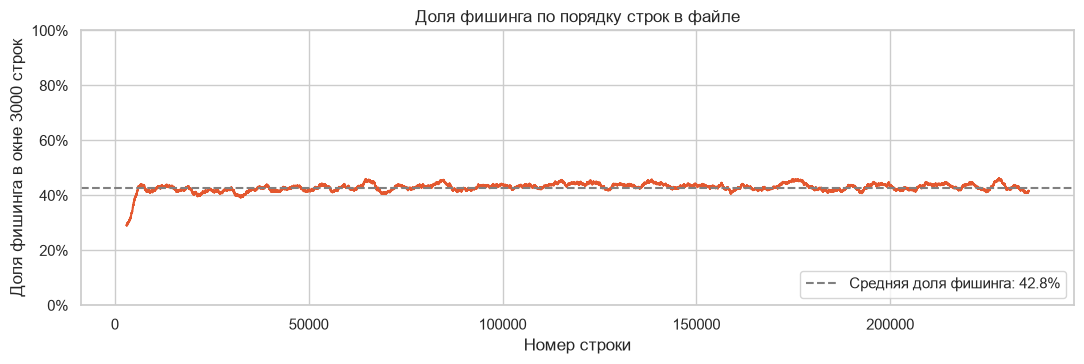

In [8]:
# Перемешаны ли строки в файле? Доля фишинга в скользящем окне по порядку строк
rolling = df[TARGET].rolling(3000).mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(rolling.values, color=PALETTE["Фишинг"], linewidth=1.5)
ax.axhline(df[TARGET].mean(), color="gray", linestyle="--", label=f"Средняя доля фишинга: {df[TARGET].mean():.1%}")
ax.set(title="Доля фишинга по порядку строк в файле", xlabel="Номер строки", ylabel="Доля фишинга в окне 3000 строк", ylim=(0, 1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

Доля фишинга в скользящем окне держится около средней (42.8%) по всему файлу - строки перемешаны,
порядок не несёт информации. Тем не менее разбиение на train/test делаем со стратификацией по `is_phishing`
и группировкой по URL (п. 5.1) - `StratifiedGroupKFold` из `scikit-learn` обеспечивает и то и другое.

## 6. Целевая переменная

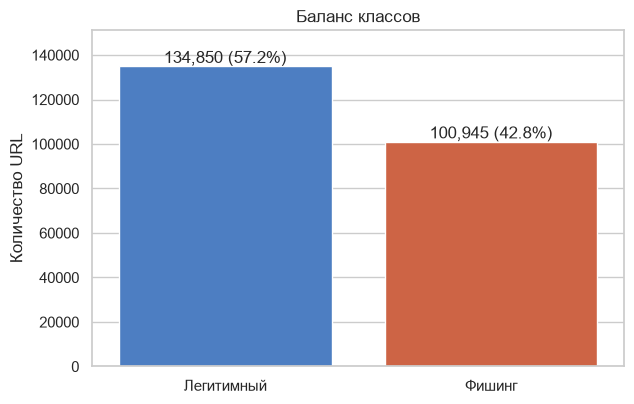

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.countplot(data=df, x="Класс", order=ORDER, hue="Класс", palette=PALETTE, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f} ({p.get_height() / len(df):.1%})",
                (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set(title="Баланс классов", xlabel="", ylabel="Количество URL")
ax.set_ylim(0, df["Класс"].value_counts().max() * 1.12)
plt.tight_layout()
plt.show()

1) 134 850 (57.2%) легитимных и 100 945 (42.8%) фишинговых URL - выборка почти сбалансирована,
   специальная балансировка классов (oversampling, веса) для обучения не требуется;
2) Это соотношение **искусственное**: в реальной почте фишинговых ссылок - доли процента. Поэтому модель нужно
   оценивать по метрикам, не зависящим от баланса (FPR, Recall), а precision пересчитывать на реальную долю (п. 2);
3) Порог классификации по умолчанию (0.5), подобранный на сбалансированной выборке, в продакшене даст слишком
   много ложных блокировок - порог надо выбирать по допустимому FPR.

## 7. Артефакты сборки датасета и утечки

Легитимные и фишинговые URL собраны из разных источников разными способами. Модель может научиться отличать
не «фишинг от не-фишинга», а «источник А от источника Б». Проверяем, нет ли таких «отпечатков».

### 7.1. Формат URL

Класс,Легитимный,Фишинг
Начинается с https://,100.0%,48.7%
Домен начинается с www.,100.0%,41.4%
Есть путь/параметры после домена,0.0%,59.9%
Оканчивается на '/',0.0%,36.5%


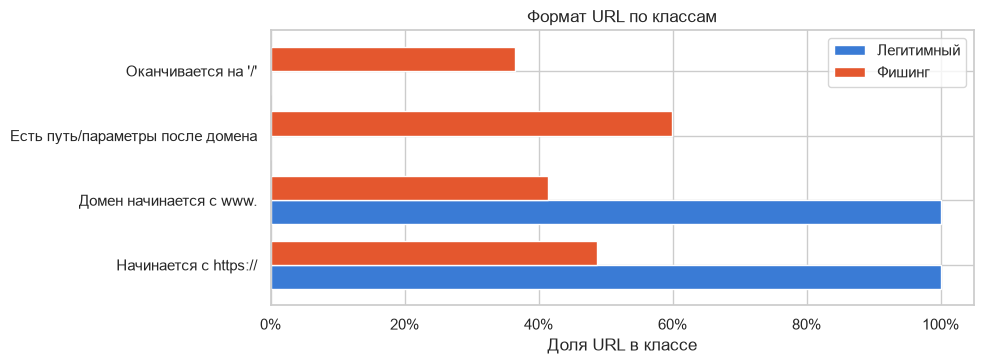

Примеры легитимных URL: ['https://www.levelup.com', 'https://www.notjusttoyz.com', 'https://www.discover-suriname.com', 'https://www.ecolabelindex.com', 'https://www.cinematheque.fr']
Примеры фишинговых URL: ['https://tracking.selfserviceib.com/tracking/1/click/ejorccw7cfkwhilpbcpgu7mn1hs1pqyi7ko2fgolwhjz20ggw-kcr8a72__zd3akduk-lwxcvp0nxybfpwan3e5aa6kl8oka0lu4jbl-eqbzd8rhbueigtfhn-_tr4o5ruxmkukw2lpciukyb8tmlpuy82to0mhbi4nvvgycrqsh_6ah-5b7zcke4-gmdzhllp8mhbogmxy1zsmnxzapvzzona4txmcjhcy8wgjul7vyp3a_7br_-n7saoen0zuabg19babghhzotbbs8lyau6vjzrlmtgvq5gvl0mf4mvqzqrjt7dnqowq325u7xq-yrni_py7e-jeltjmwh3ggi7oiiqfqavqmqyod55dwk6ctni0g9jvrtq_-uxqfuby_-ww22kni20qibyi8umza5x-6ejwpetbdo8qzvokooez2wvn2qvknqxe0tkc8-vh32c6a8epif2boookcm3vy531pl3ybajw4hb8ptdqzvrn5msoglsqbfgrq_juupjivt7opnhuid1l5tn0y5qymkejl5r9xpeamisa4cw1k0tgyug9-cfaatrekgjierw8mro_ptcfwffs_u3az1xykptx6sdvvyrt7yjfrbv50xw1-rf5e9bphdwlhgjvjoqcep1aj8cmbbutzfd_k5nribufd41uofrto7dcauzdix5swalpohd0wxekhpcnsucyv_qhlejjb9n7kele-8r_m3a==', 'https:

In [10]:
# Формат URL: схема, www, наличие пути после домена, слэш в конце
no_scheme = df["URL"].str.replace(r"^https?://", "", regex=True)
url_fmt = pd.DataFrame({
    "Начинается с https://": df["URL"].str.startswith("https://"),
    "Домен начинается с www.": no_scheme.str.startswith("www."),
    "Есть путь/параметры после домена": no_scheme.str.contains("/"),
    "Оканчивается на '/'": df["URL"].str.endswith("/"),
})
fmt_share = url_fmt.groupby(df["Класс"]).mean().T[ORDER]
display(fmt_share.style.format("{:.1%}"))

ax = fmt_share.plot.barh(figsize=(10, 3.8), color=[PALETTE[c] for c in ORDER], width=0.75)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Формат URL по классам", xlabel="Доля URL в классе", ylabel="")
ax.legend(title="")
plt.tight_layout()
plt.show()

print("Примеры легитимных URL:", df.loc[df[TARGET] == 0, "URL"].sample(5, random_state=1).tolist())
print("Примеры фишинговых URL:", df.loc[df[TARGET] == 1, "URL"].sample(5, random_state=1).tolist())

**Все легитимные URL имеют один и тот же формат:** `https://www.<домен>` - без пути, параметров и слэша в конце.
Это главные страницы популярных сайтов. Среди фишинга https только у 48.7%, `www.` - у 41.4%, а у 59.9% есть путь
после домена (`/login`, `/ipfs/...`, `/wp-admin/...`).

В реальном трафике всё иначе: пользователи переходят по ссылкам на конкретные страницы (`/docs/...`, `/news/...`),
и часть легитимных сайтов работает без `www.`. Модель, обученная на этих данных, может выучить правило
«есть путь в URL - значит фишинг» и давать массу ложных блокировок на обычных ссылках из писем.

Следствия для предобработки:
- признаки, кодирующие формат («есть путь», «есть www», `IsHTTPS`), надо использовать осторожно и проверять
  модель на отдельной выборке реальных легитимных URL с путями;
- либо привести URL к общему виду (оставить только домен) и обучать модель на признаках домена и страницы.

### 7.2. Насколько хорошо разделяет классы каждый признак в одиночку

Используем значение признака как оценку и считаем ROC-AUC. Если один признак даёт AUC около 1.0 -
это либо идеальный признак, либо утечка, и такой признак требует отдельной проверки.

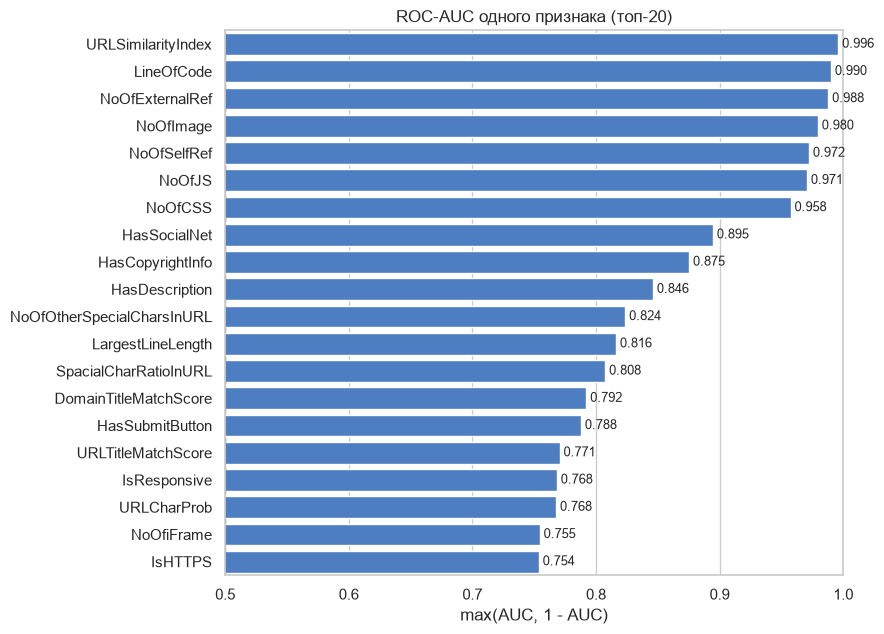

Признаков с AUC > 0.95 в одиночку: 7 из 50


In [11]:
# ROC-AUC каждого признака по отдельности (значение признака используется как скор).
# 0.5 - признак бесполезен, 1.0 - признак в одиночку идеально разделяет классы.
# Направление связи не важно, поэтому берём max(AUC, 1 - AUC).
single_auc = {}
for c in num_cols:
    auc = roc_auc_score(df[TARGET], df[c])
    single_auc[c] = max(auc, 1 - auc)
single_auc = pd.Series(single_auc).sort_values(ascending=False)

top = single_auc.head(20)
fig, ax = plt.subplots(figsize=(9, 6.5))
sns.barplot(x=top.values, y=top.index, color=PALETTE["Легитимный"], ax=ax)
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set(title="ROC-AUC одного признака (топ-20)", xlabel="max(AUC, 1 - AUC)", ylabel="", xlim=(0.5, 1.0))
for i, v in enumerate(top.values):
    ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

print("Признаков с AUC > 0.95 в одиночку:", (single_auc > 0.95).sum(), "из", len(single_auc))

1) **7 признаков в одиночку дают AUC > 0.95**: `URLSimilarityIndex` (0.996), `LineOfCode` (0.990), `NoOfExternalRef` (0.988),
   `NoOfImage`, `NoOfSelfRef`, `NoOfJS`, `NoOfCSS` (0.96-0.98). Для реальной задачи фишинга это неправдоподобно высокие значения;
2) Шесть из семи - признаки «объёма» HTML-страницы: у фишинга страница почти пустая (разбираем в п. 8.3-8.4);
3) Первое место занимает `URLSimilarityIndex` - разберём его отдельно.

### 7.3. `URLSimilarityIndex`

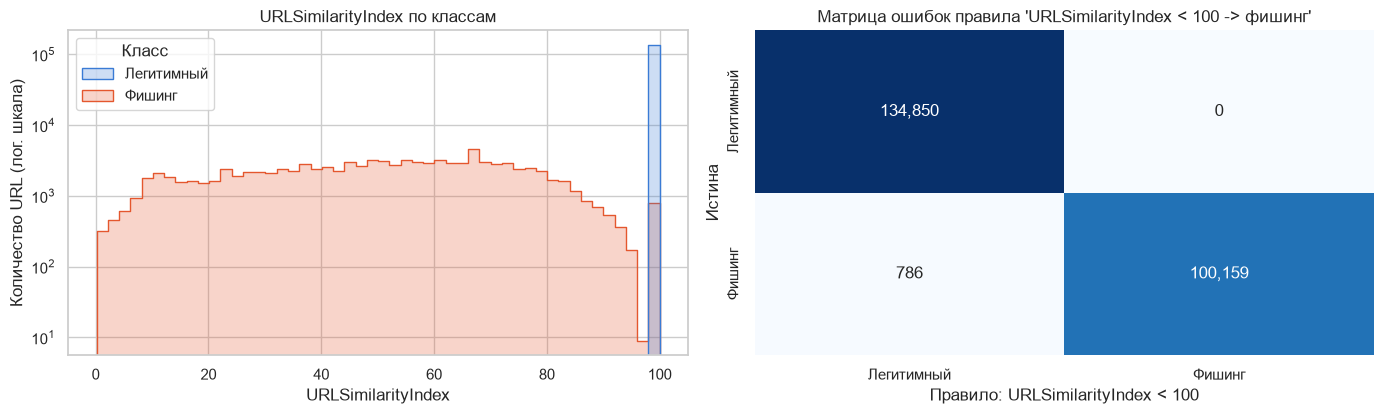

Accuracy правила: 0.9967
Recall: 0.9922,  Precision: 1.0000
Доля URLSimilarityIndex == 100 по классам: {'Легитимный': 1.0, 'Фишинг': 0.0078}


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
sns.histplot(data=df, x="URLSimilarityIndex", hue="Класс", hue_order=ORDER, palette=PALETTE,
             bins=50, element="step", stat="count", ax=axes[0])
axes[0].set_yscale("log")
axes[0].set(title="URLSimilarityIndex по классам", ylabel="Количество URL (лог. шкала)")

# Простейшее правило из одного условия
rule_pred = (df["URLSimilarityIndex"] < 100).astype(int)
cm = pd.crosstab(df["Класс"], rule_pred.map({0: "Легитимный", 1: "Фишинг"}),
                 rownames=["Истина"], colnames=["Правило: URLSimilarityIndex < 100"])
sns.heatmap(cm.loc[ORDER, ORDER], annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set(title="Матрица ошибок правила 'URLSimilarityIndex < 100 -> фишинг'")
plt.tight_layout()
plt.show()

tp = ((rule_pred == 1) & (df[TARGET] == 1)).sum()
print(f"Accuracy правила: {(rule_pred == df[TARGET]).mean():.4f}")
print(f"Recall: {tp / df[TARGET].sum():.4f},  Precision: {tp / rule_pred.sum():.4f}")
print("Доля URLSimilarityIndex == 100 по классам:", (df["URLSimilarityIndex"] == 100).groupby(df["Класс"]).mean().round(4).to_dict())

**`URLSimilarityIndex` - утечка целевой переменной.** У 100% легитимных URL значение ровно 100,
у фишинга - лишь у 0.8%. Правило из одного условия `URLSimilarityIndex < 100 → фишинг` даёт accuracy 99.67%,
precision 100% и recall 99.2%.

Причина - в способе расчёта: индекс сравнивает URL с эталонным списком легитимных URL, из которого, судя по
всему, и взяты легитимные объекты датасета. Каждый легитимный URL «похож сам на себя» на 100%. В продакшене
легитимная ссылка из письма (например, на конкретную статью) в такой список не входит, и признак потеряет
свою силу.

Признак нужно **исключить** из основной модели (или обучить две модели - с ним и без него - и показать разницу).
Иначе любая модель покажет ~99.7% и ничего не будет знать о фишинге.

### 7.4. Признаки, постоянные внутри легитимного класса

In [13]:
# Признаки, которые принимают одно значение во ВСЁМ легитимном классе
legit = df[df[TARGET] == 0]
const_in_legit = {c: legit[c].iloc[0] for c in num_cols if legit[c].nunique() == 1}
rows = []
for c, v in const_in_legit.items():
    rows.append({"Признак": c, "Значение у всех легитимных": v,
                 "Доля фишинга с таким же значением": (df.loc[df[TARGET] == 1, c] == v).mean()})
display(pd.DataFrame(rows).sort_values("Доля фишинга с таким же значением"))

# Если убрать признаки-«отпечатки» сборки, разделение ослабевает?
print("Доля легитимных среди URL без пути, с https:// и www.:",
      round(1 - df.loc[url_fmt.iloc[:, :2].all(axis=1) & ~url_fmt.iloc[:, 2], TARGET].mean(), 3))

,Признак,Значение у всех легитимных,Доля фишинга с таким же значением
1,URLSimilarityIndex,100.000,0.008
8,IsHTTPS,1.000,0.492
6,NoOfQMarkInURL,0.000,0.939
5,NoOfEqualsInURL,0.000,0.946
7,NoOfAmpersandInURL,0.000,0.991
0,IsDomainIP,0.000,0.994
3,NoOfObfuscatedChar,0.000,0.995
2,HasObfuscation,0.000,0.995
4,ObfuscationRatio,0.000,0.995


Доля легитимных среди URL без пути, с https:// и www.: 0.995


1) Девять признаков принимают **одно и то же значение у всех 134 850 легитимных URL**: `URLSimilarityIndex = 100`,
   `IsHTTPS = 1`, а также нули у `NoOfQMarkInURL`, `NoOfEqualsInURL`, `NoOfAmpersandInURL`, `IsDomainIP` и признаков обфускации;
2) Особенно опасен `IsHTTPS`: правило «нет https → фишинг» не ошибается на легитимных никогда. В реальности
   http-сайты ещё встречаются, а большинство фишинговых сайтов давно используют бесплатные TLS-сертификаты
   (здесь - почти половина);
3) URL формата `https://www.<домен>` без пути на 99.5% легитимны - формат URL сам по себе почти идеально задаёт класс.

Вывод: значительная часть «силы» URL-признаков в этом датасете объясняется различием источников данных, а не
природой фишинга. Это нужно учитывать при интерпретации высокого качества моделей.

## 8. Числовые признаки

### 8.1. Асимметрия распределений

Коэффициент асимметрии (skewness) равен 0 у симметричного распределения. Сравним `LineOfCode` в исходной шкале и после
`log1p(x) = log(1 + x)` (единица добавляется, потому что в признаках есть нули).

,NoOfCSS,NoOfObfuscatedChar,NoOfJS,NoOfEqualsInURL,NoOfEmptyRef,NoOfAmpersandInURL,NoOfiFrame,NoOfDegitsInURL,NoOfPopup,NoOfExternalRef,NoOfSelfRef,NoOfLettersInURL
Асимметрия,464.404,204.684,140.436,114.985,106.826,106.717,97.677,94.878,84.953,65.900,60.381,58.403


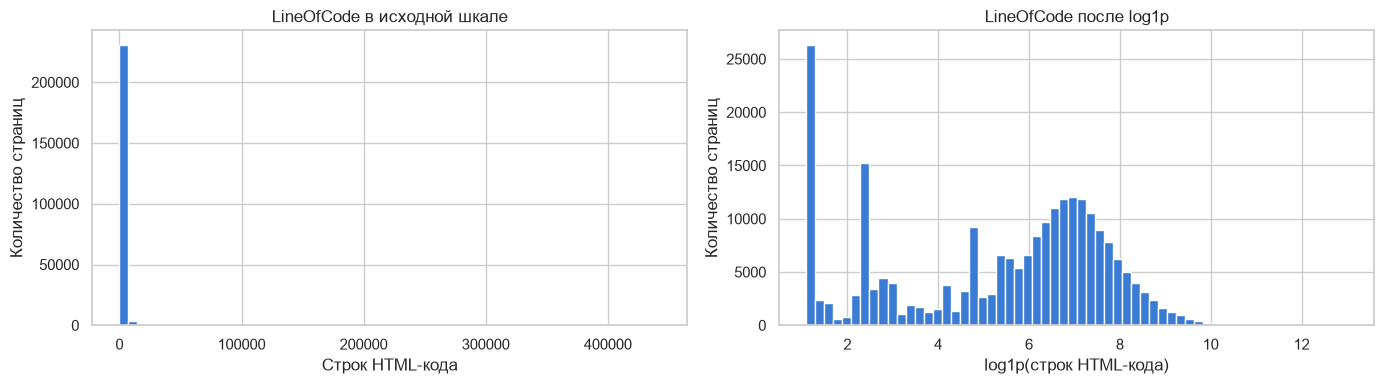

In [14]:
skew = df[cont_cols].skew().sort_values(ascending=False)
display(skew.head(12).to_frame("Асимметрия").T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df["LineOfCode"], bins=60, color=PALETTE["Легитимный"])
axes[0].set(title="LineOfCode в исходной шкале", xlabel="Строк HTML-кода", ylabel="Количество страниц")
axes[1].hist(np.log1p(df["LineOfCode"]), bins=60, color=PALETTE["Легитимный"])
axes[1].set(title="LineOfCode после log1p", xlabel="log1p(строк HTML-кода)", ylabel="Количество страниц")
plt.tight_layout()
plt.show()

1) Асимметрия счётных признаков огромна: у `NoOfCSS` - 464, у `NoOfJS` - 140, у `NoOfExternalRef` - 66;
2) В исходной шкале гистограмма `LineOfCode` вырождается в один столбец у нуля; после `log1p` видна структура:
   пик фишинговых «пустых» страниц слева и колокол нормальных сайтов (~1 000 строк) справа;
3) Для линейных моделей и kNN счётные признаки (`LineOfCode`, `LargestLineLength`, `NoOf*`, `URLLength`) нужно логарифмировать
   и затем стандартизировать. Деревьям решений это не требуется - им важен только порядок значений.

### 8.2. Признаки URL по классам

Используется нормировка внутри класса (`common_norm=False`), чтобы сравнивать форму распределений,
а не размеры классов. Для длины URL и числа букв - логарифмическая ось.

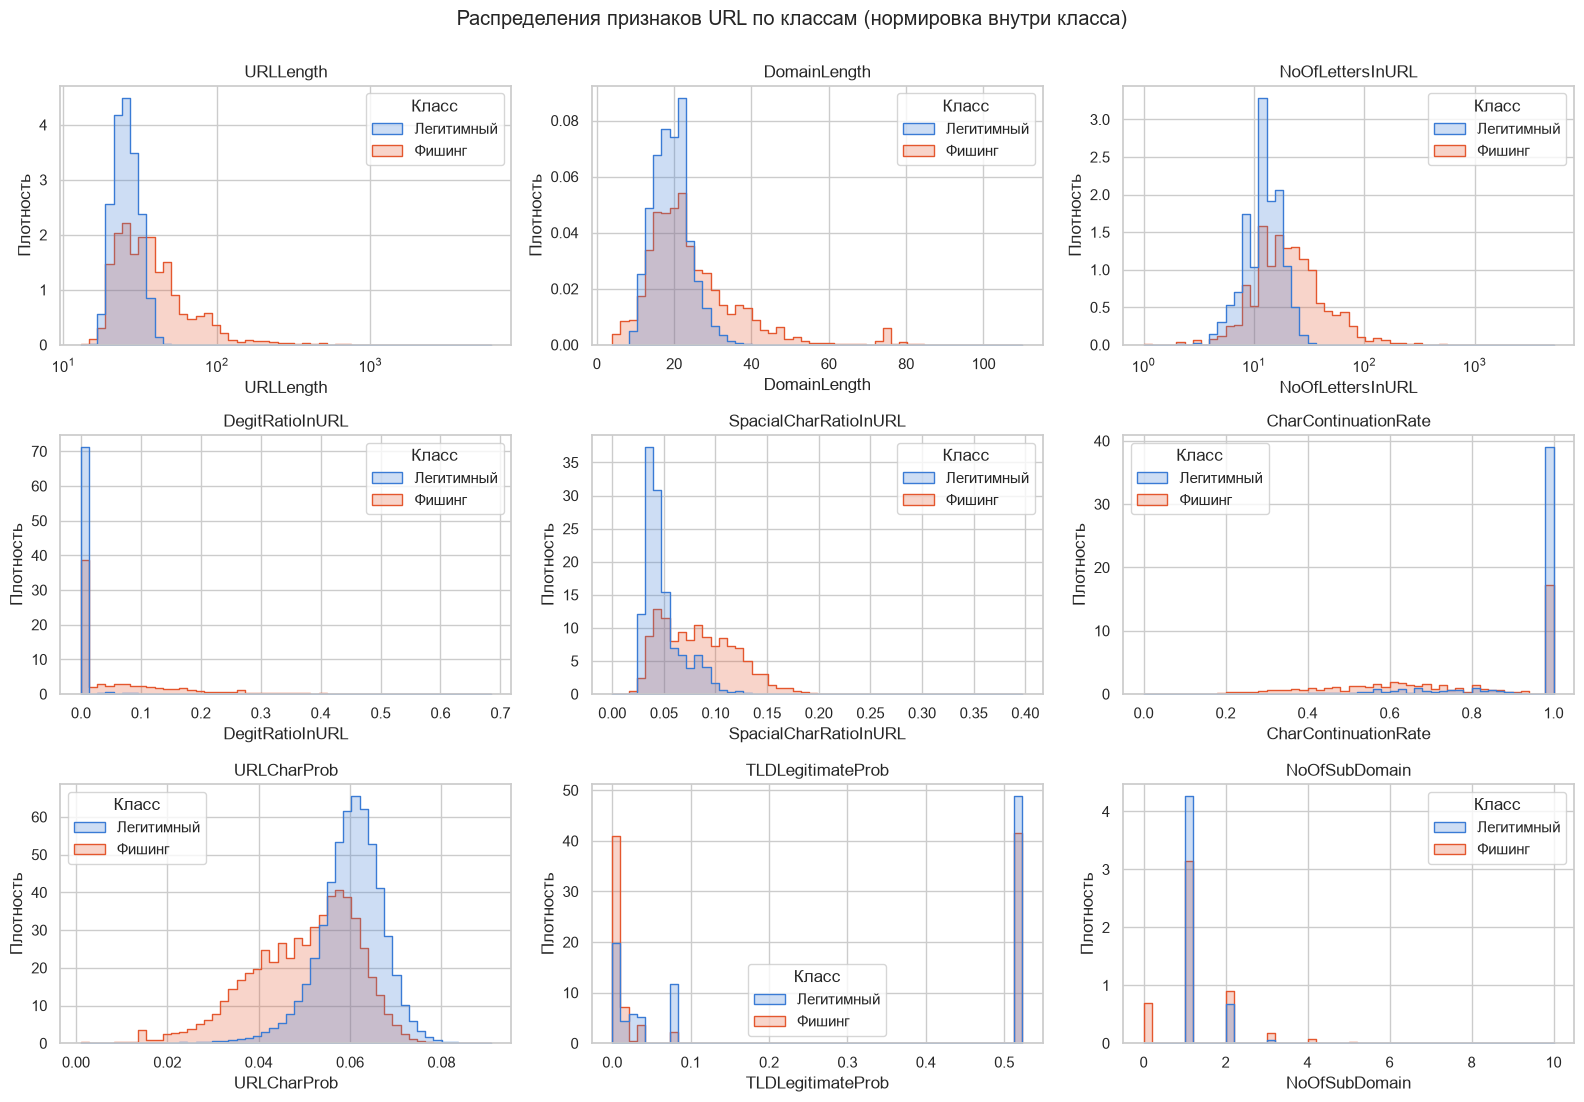

,URLLength,DomainLength,NoOfLettersInURL,DegitRatioInURL,SpacialCharRatioInURL,CharContinuationRate,URLCharProb,TLDLegitimateProb,NoOfSubDomain
Класс,,,,,,,,,
Легитимный,26.000,19.000,13.000,0.000,0.042,1.000,0.061,0.523,1.000
Фишинг,34.000,22.000,20.000,0.000,0.080,0.727,0.052,0.018,1.000


In [15]:
url_plot_cols = ["URLLength", "DomainLength", "NoOfLettersInURL", "DegitRatioInURL",
                 "SpacialCharRatioInURL", "CharContinuationRate", "URLCharProb", "TLDLegitimateProb", "NoOfSubDomain"]

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.flat, url_plot_cols):
    sns.histplot(data=df, x=col, hue="Класс", hue_order=ORDER, palette=PALETTE, bins=50,
                 stat="density", common_norm=False, element="step", ax=ax,
                 log_scale=(col in ("URLLength", "NoOfLettersInURL")))
    ax.set(title=col, ylabel="Плотность")
plt.suptitle("Распределения признаков URL по классам (нормировка внутри класса)", y=1.0)
plt.tight_layout()
plt.show()

display(df.groupby("Класс")[url_plot_cols].median().loc[ORDER])

1) **Длина.** Легитимные URL короткие и однородные (медиана 26 символов, максимум 57) - это следствие того, что
   в выборке только главные страницы. Фишинговые URL длиннее (медиана 34) и с длинным хвостом до тысяч символов;
2) **Доля спецсимволов и цифр** выше у фишинга (медианная `SpacialCharRatioInURL` 0.080 против 0.042): дефисы,
   цифры и случайные строки в автоматически сгенерированных доменах (`caseid1008934573489573489.firebaseapp.com`);
3) **`CharContinuationRate` и `URLCharProb`** ниже у фишинга: «случайный» вид строки, нетипичные сочетания символов -
   признак сгенерированных или замаскированных под бренд доменов. Эти признаки отражают реальное свойство фишинга;
4) **`TLDLegitimateProb`**: у 54% фишинга значение около 0 (редкие/дешёвые TLD), но у 43% - максимальное
   0.523 (`com`). Признак полезен, но фактически дублирует `TLD` (п. 9);
5) `NoOfSubDomain` почти не различается по классам (медиана 1 у обоих); ноль поддоменов чаще у фишинга
   (у легитимных всегда есть `www`).

### 8.3. Признаки HTML-страницы по классам (после `log1p`)

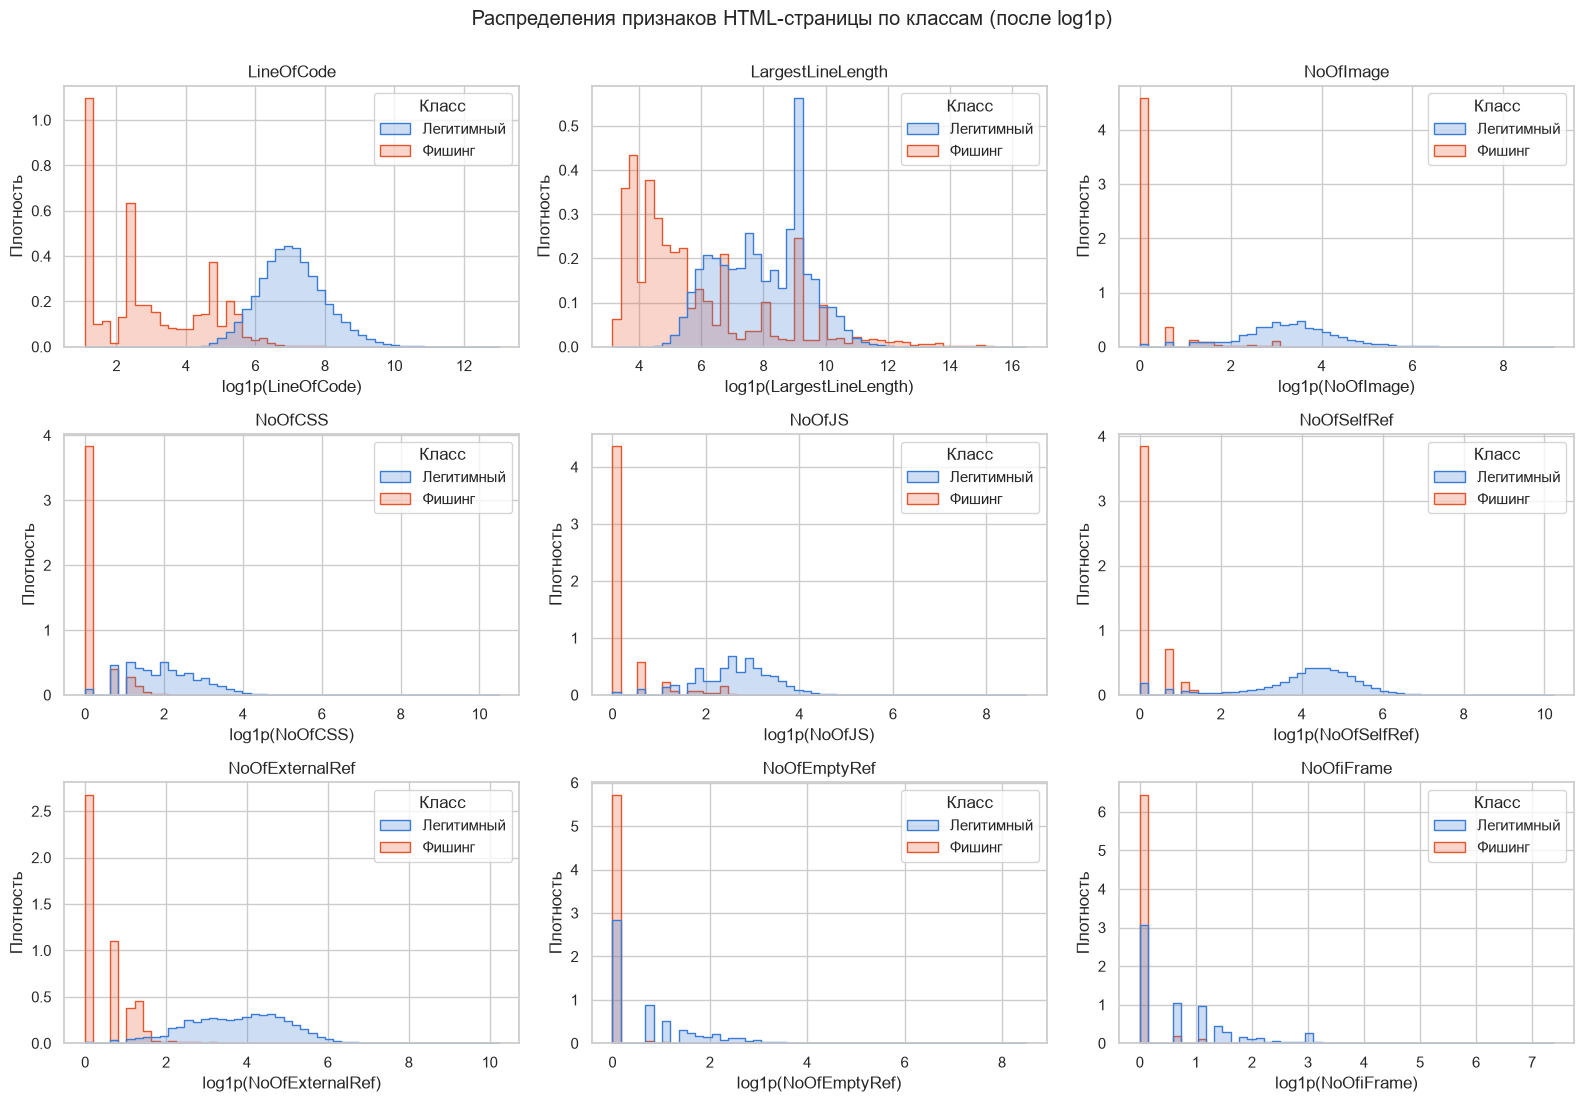

,LineOfCode,LargestLineLength,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfExternalRef,NoOfEmptyRef,NoOfiFrame
Класс,,,,,,,,,
Легитимный,"1,105.000","3,066.000",25.000,6.000,14.000,76.000,46.000,1.000,1.000
Фишинг,12.000,138.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


Доля страниц короче 10 строк HTML: {'Легитимный': 0.0, 'Фишинг': 0.457}
Доля страниц без внешних и внутренних ссылок: {'Легитимный': 0.0, 'Фишинг': 0.51}


In [16]:
html_plot_cols = ["LineOfCode", "LargestLineLength", "NoOfImage", "NoOfCSS", "NoOfJS",
                  "NoOfSelfRef", "NoOfExternalRef", "NoOfEmptyRef", "NoOfiFrame"]

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.flat, html_plot_cols):
    sns.histplot(x=np.log1p(df[col]), hue=df["Класс"], hue_order=ORDER, palette=PALETTE, bins=50,
                 stat="density", common_norm=False, element="step", ax=ax)
    ax.set(title=col, xlabel=f"log1p({col})", ylabel="Плотность")
plt.suptitle("Распределения признаков HTML-страницы по классам (после log1p)", y=1.0)
plt.tight_layout()
plt.show()

display(df.groupby("Класс")[html_plot_cols].median().loc[ORDER])
print("Доля страниц короче 10 строк HTML:", (df["LineOfCode"] < 10).groupby(df["Класс"]).mean().round(3).to_dict())
print("Доля страниц без внешних и внутренних ссылок:",
      ((df["NoOfExternalRef"] + df["NoOfSelfRef"]) == 0).groupby(df["Класс"]).mean().round(3).to_dict())

1) Распределения практически не пересекаются: медианная легитимная страница - 1 105 строк HTML, 25 изображений,
   14 скриптов, 76 внутренних и 46 внешних ссылок; **медианная фишинговая - 12 строк и ноль всего остального**;
2) 45.7% фишинговых страниц короче 10 строк, а у половины (51%) нет ни одной ссылки. Среди легитимных таких нет вовсе;
3) Настоящая фишинговая страница входа в Microsoft 365 или банк - это полноценная копия оригинала с CSS, JS и картинками.
   10 строк HTML - это не фишинговая страница, а **заглушка**: «сайт заблокирован», «suspended», пустой ответ
   или редирект. Скорее всего, HTML скачивался уже после того, как хостинг удалил фишинговый контент.
   Проверим это в следующем пункте.

### 8.4. «Мёртвые» фишинговые страницы

Доля страниц с >= 100 строк HTML: {'Легитимный': 1.0, 'Фишинг': 0.233}


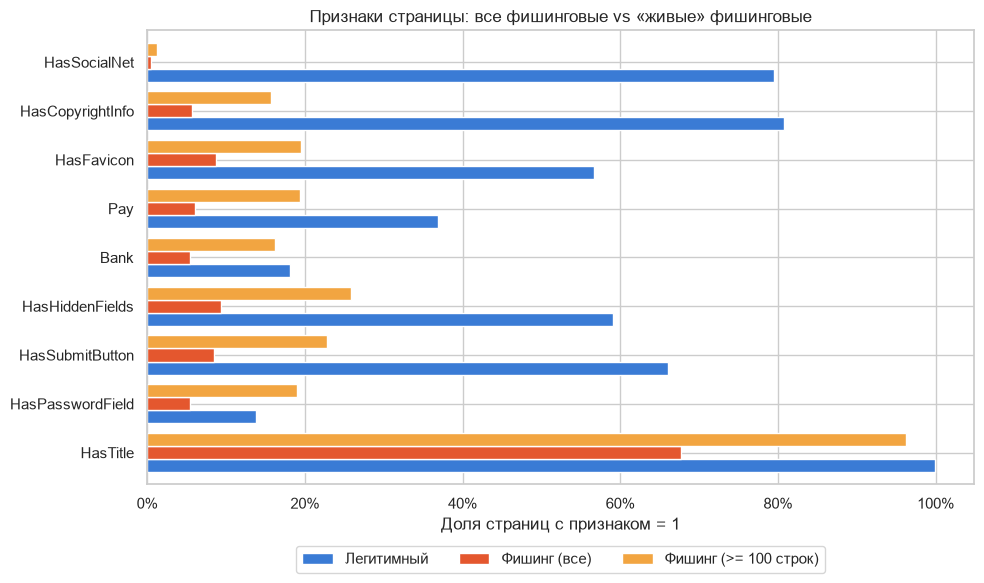

,Легитимный,Фишинг (все),Фишинг (>= 100 строк)
HasTitle,99.9%,67.8%,96.3%
HasPasswordField,13.8%,5.4%,19.0%
HasSubmitButton,66.1%,8.5%,22.8%
HasHiddenFields,59.1%,9.3%,25.8%
Bank,18.2%,5.4%,16.3%
Pay,36.9%,6.0%,19.3%
HasFavicon,56.7%,8.8%,19.6%
HasCopyrightInfo,80.8%,5.7%,15.7%
HasSocialNet,79.5%,0.5%,1.3%


In [17]:
# Гипотеза: большая часть фишинговых страниц скачана уже после блокировки (заглушка хостинга).
# Сравним «живые» фишинговые страницы (>= 100 строк HTML) с легитимными.
alive = df["LineOfCode"] >= 100
print("Доля страниц с >= 100 строк HTML:", alive.groupby(df["Класс"]).mean().round(3).to_dict())

form_cols = ["HasTitle", "HasPasswordField", "HasSubmitButton", "HasHiddenFields", "Bank", "Pay",
             "HasFavicon", "HasCopyrightInfo", "HasSocialNet"]
alive_cmp = pd.DataFrame({
    "Легитимный": df.loc[df[TARGET] == 0, form_cols].mean(),
    "Фишинг (все)": df.loc[df[TARGET] == 1, form_cols].mean(),
    "Фишинг (>= 100 строк)": df.loc[(df[TARGET] == 1) & alive, form_cols].mean(),
})

ax = alive_cmp.plot.barh(figsize=(10, 6), width=0.8,
                         color=[PALETTE["Легитимный"], PALETTE["Фишинг"], "#f2a541"])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Признаки страницы: все фишинговые vs «живые» фишинговые", xlabel="Доля страниц с признаком = 1", ylabel="")
ax.legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout()
plt.show()
display(alive_cmp.style.format("{:.1%}"))

1) Только 23.3% фишинговых страниц содержат хотя бы 100 строк HTML (у легитимных - 100%);
2) Если смотреть на все фишинговые страницы, получается парадокс: поле ввода пароля (`HasPasswordField`) чаще встречается
   у легитимных сайтов (13.8%), чем у фишинга (5.4%). То же с упоминанием банков и платежей;
3) Среди «живых» фишинговых страниц картина ожидаемая: **поле пароля у 19.0%** - чаще, чем у легитимных, `HasTitle` - у 96%,
   упоминания банков - у 16%. Но и у «живого» фишинга почти нет ссылок на соцсети (1.3% против 79.5%) и копирайта (15.7% против 80.8%) -
   фишинговая страница копирует только форму входа, а не весь сайт.

**Вывод:** HTML-признаки в датасете во многом описывают не фишинговую страницу, а **момент её скачивания**
(живая/удалённая). Модель, обученная на них, научится правилу «пустая страница → фишинг» и будет пропускать
свежие, ещё работающие фишинговые сайты - то есть ровно те, ради которых она нужна. При подготовке данных стоит:
- добавить явный признак «страница-заглушка» или отделить такие объекты;
- оценивать качество отдельно на «живых» фишинговых страницах (это более честная оценка для продакшена).

### 8.5. Бинарные признаки

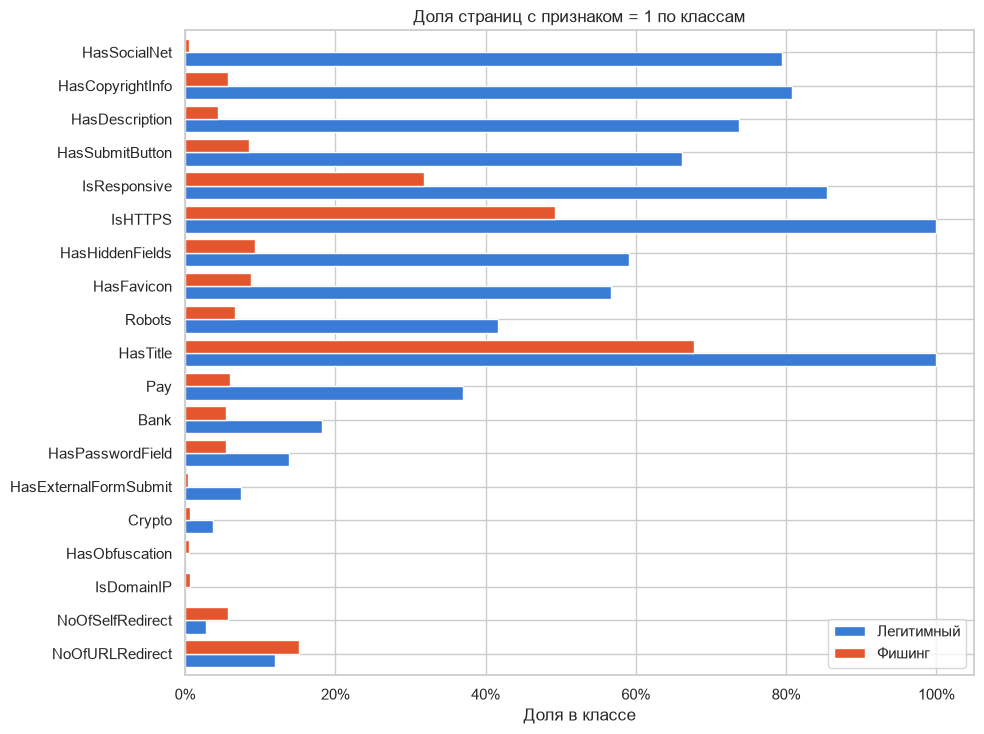

Класс,Легитимный,Фишинг,Разница
NoOfURLRedirect,12.0%,15.2%,-3.2%
NoOfSelfRedirect,2.7%,5.7%,-3.0%
IsDomainIP,0.0%,0.6%,-0.6%
HasObfuscation,0.0%,0.5%,-0.5%
Crypto,3.7%,0.6%,3.0%
HasExternalFormSubmit,7.4%,0.4%,6.9%
HasPasswordField,13.8%,5.4%,8.5%
Bank,18.2%,5.4%,12.7%
Pay,36.9%,6.0%,30.9%
HasTitle,99.9%,67.8%,32.1%


In [18]:
bin_share = df.groupby("Класс")[binary_cols].mean().T[ORDER]
bin_share["Разница"] = bin_share["Легитимный"] - bin_share["Фишинг"]
bin_share = bin_share.sort_values("Разница")

ax = bin_share[ORDER].plot.barh(figsize=(10, 7.5), color=[PALETTE[c] for c in ORDER], width=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="Доля страниц с признаком = 1 по классам", xlabel="Доля в классе", ylabel="")
ax.legend(title="", loc="lower right")
plt.tight_layout()
plt.show()

display(bin_share.style.format("{:.1%}"))

1) Наибольшая разница - у признаков «зрелого» сайта: `HasSocialNet` (79.5% против 0.5%), `HasCopyrightInfo` (80.8% против 5.7%),
   `HasDescription` (73.7% против 4.4%), `HasSubmitButton`, `IsResponsive`. Отчасти это реальный сигнал (фишинговая страница
   - одностраничник без футера), отчасти - эффект «мёртвых» страниц из п. 8.4;
2) `IsHTTPS` и `HasTitle` у легитимных равны 100% - артефакты отбора (п. 7.4);
3) Признаки, которые по смыслу должны указывать на фишинг (`HasPasswordField`, `Bank`, `Pay`, `Crypto`, `HasExternalFormSubmit`),
   на всей выборке чаще встречаются у легитимных сайтов - из-за того же эффекта. Линейная модель получит у них
   «неправильный» знак веса;
4) Только `NoOfURLRedirect`, `NoOfSelfRedirect`, `IsDomainIP` и `HasObfuscation` чаще встречаются у фишинга, но последние
   два - очень редкие (< 1%).

## 9. Домен верхнего уровня (TLD)

Уникальных TLD: 695


TLD,com,org,net,app,uk,co,io,de,ru,au,dev,top,jp,it,edu
Количество,"112,554.000","18,793.000","7,097.000","6,508.000","6,395.000","5,422.000","4,201.000","3,996.000","3,875.000","2,979.000","2,345.000","2,329.000","2,219.000","1,887.000","1,861.000"
Доля_фишинга,0.389,0.121,0.437,0.978,0.050,0.916,0.897,0.172,0.770,0.125,0.986,0.999,0.062,0.116,0.003


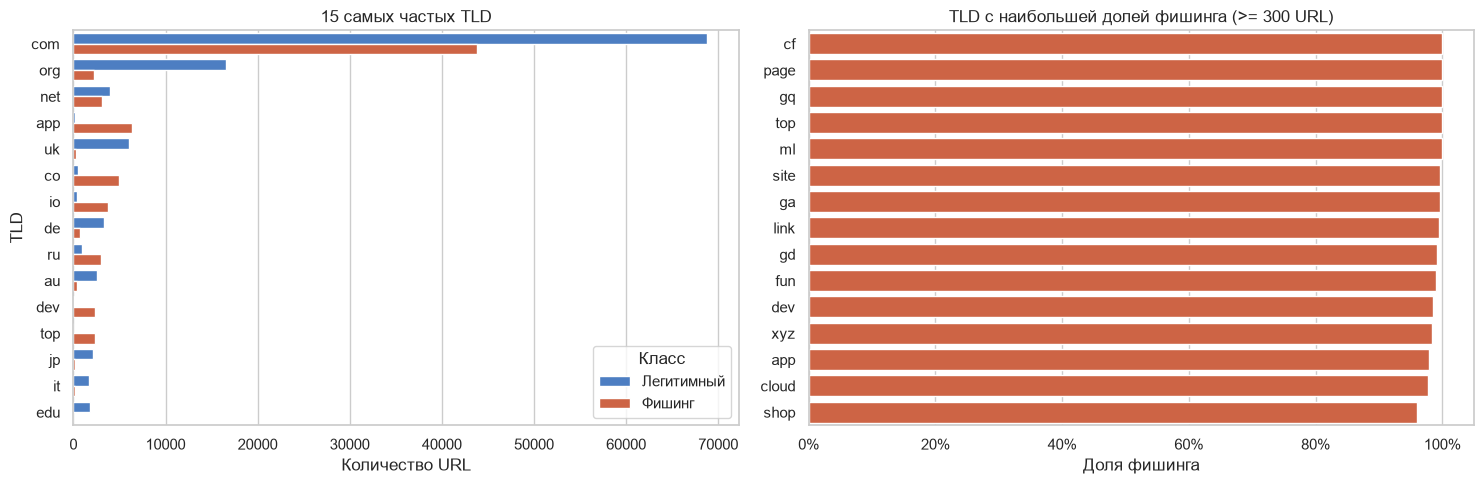

TLD с числом URL < 50: 552 (4,362 URL)


In [19]:
tld_summary = (
    df.groupby("TLD")[TARGET]
      .agg(Количество="size", Доля_фишинга="mean")
      .sort_values("Количество", ascending=False)
)
print(f"Уникальных TLD: {len(tld_summary)}")
display(tld_summary.head(15).T)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_tld = tld_summary.index[:15]
sns.countplot(data=df[df["TLD"].isin(top_tld)], y="TLD", hue="Класс", order=top_tld,
              hue_order=ORDER, palette=PALETTE, ax=axes[0])
axes[0].set(title="15 самых частых TLD", xlabel="Количество URL", ylabel="TLD")

# TLD, встречающиеся хотя бы 300 раз, с самой высокой долей фишинга
risky = tld_summary[tld_summary["Количество"] >= 300].sort_values("Доля_фишинга", ascending=False).head(15)
sns.barplot(x=risky["Доля_фишинга"], y=risky.index, color=PALETTE["Фишинг"], ax=axes[1])
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set(title="TLD с наибольшей долей фишинга (>= 300 URL)", xlabel="Доля фишинга", ylabel="")
plt.tight_layout()
plt.show()

rare = tld_summary[tld_summary["Количество"] < 50]
print(f"TLD с числом URL < 50: {len(rare)} ({rare['Количество'].sum():,} URL)")

1) TLD - сильный признак: `top` (99.9% фишинга), `dev` (98.6%), `app` (97.8%), `co` (91.6%), `io` (89.7%), а также
   бесплатные TLD `cf`, `gq`, `ml`, `ga` - почти 100% фишинга. Это согласуется с практикой: фишеры используют дешёвые
   или бесплатные домены и бесплатные хостинги (`*.web.app`, `*.pages.dev`, `*.github.io`);
2) Обратная сторона - `edu` (0.3%), `uk` (5%), `jp` (6%) почти полностью легитимны. Высокая доля фишинга в `app` и `dev`
   - отчасти артефакт: легитимные URL взяты из рейтинга старых популярных доменов, где новых TLD почти нет. В реальности
   на `.app` и `.dev` работает много легальных сервисов, и модель будет давать на них ложные срабатывания;
3) 695 значений, из них 552 TLD встречаются реже 50 раз (4 362 URL). Для кодирования: оставить ~30 частых TLD +
   `other`, либо target encoding с регуляризацией (по фолдам кросс-валидации, иначе - утечка).

## 10. Выбросы

Ящик с усами показывает медиану, квартили и точки за 1.5 межквартильного размаха.
Шкала `symlog` позволяет отобразить нули и миллионы на одном графике.

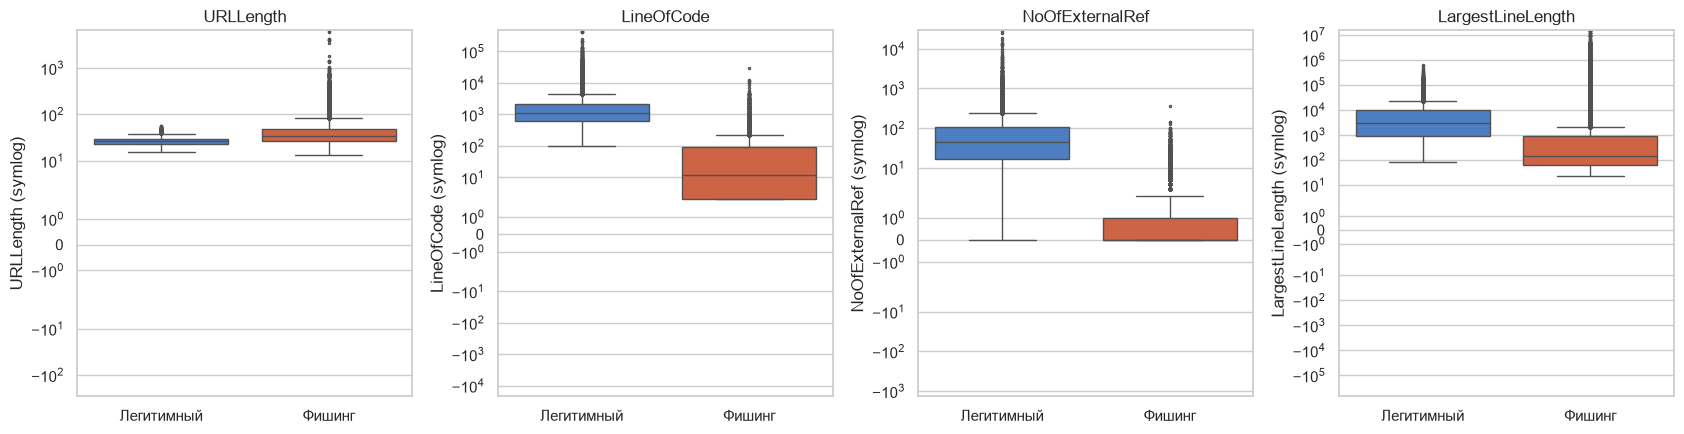

,URLLength,LineOfCode,NoOfExternalRef,LargestLineLength
Класс,,,,
Легитимный,1.3%,9.0%,6.6%,6.9%
Фишинг,9.6%,6.9%,14.8%,20.1%


,URL,URLLength,Класс
102933,https://xwebhostapp.github.io/freehost//#eyj2z...,6097,Фишинг
9650,https://b4e921f0.sso-mailsrvr-4344e5teed.pages...,5794,Фишинг
150870,https://bodhicardstech.com/beta/wx%20qz%20xx%2...,4274,Фишинг
145392,https://inspirationalatmospheres.com/qxzrrr%20...,4246,Фишинг
152736,https://bodhicardstech.com/beta/wx%20qz%20xx%2...,4054,Фишинг


In [20]:
out_cols = ["URLLength", "LineOfCode", "NoOfExternalRef", "LargestLineLength"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, col in zip(axes, out_cols):
    sns.boxplot(data=df, x="Класс", y=col, order=ORDER, hue="Класс", palette=PALETTE,
                legend=False, ax=ax, fliersize=1.5)
    ax.set_yscale("symlog")
    ax.set(title=col, xlabel="", ylabel=f"{col} (symlog)")
plt.tight_layout()
plt.show()

# Доля выбросов по правилу 1.5 IQR в каждом классе
def iqr_outlier_share(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

display(df.groupby("Класс")[out_cols].agg(iqr_outlier_share).loc[ORDER].style.format("{:.1%}"))
display(df.nlargest(5, "URLLength")[["URL", "URLLength", "Класс"]].assign(URL=lambda d: d["URL"].str[:90] + "..."))

1) По правилу 1.5 IQR выбросов много в обоих классах (от 1% до 20% в зависимости от признака), но это не ошибки измерения,
   а естественные тяжёлые хвосты;
2) Самые длинные URL (4-6 тысяч символов) - все фишинговые: длинный «хвост» из случайных символов, `%20` или base64
   используется, чтобы спрятать реальный домен за пределами видимой части адресной строки и обойти сигнатуры.
   Это **информативные** выбросы - удалять их нельзя;
3) `LargestLineLength` у фишинга чаще выбивается вверх (20% выбросов): минифицированный или обфусцированный JS одной строкой;
4) Вместо удаления выбросов - логарифмирование (п. 8.1), клиппинг по 99.9-му перцентилю для линейных моделей
   или устойчивые к выбросам модели (деревья, бустинг).

## 11. Корреляции

### 11.1. Корреляции между признаками

Используем корреляцию Спирмена, а не Пирсона: распределения сильно скошены (п. 8.1), а Спирмен работает с рангами
и улавливает любую монотонную связь. Отдельно выводим пары с |rho| > 0.9 - почти дублирующие друг друга признаки.

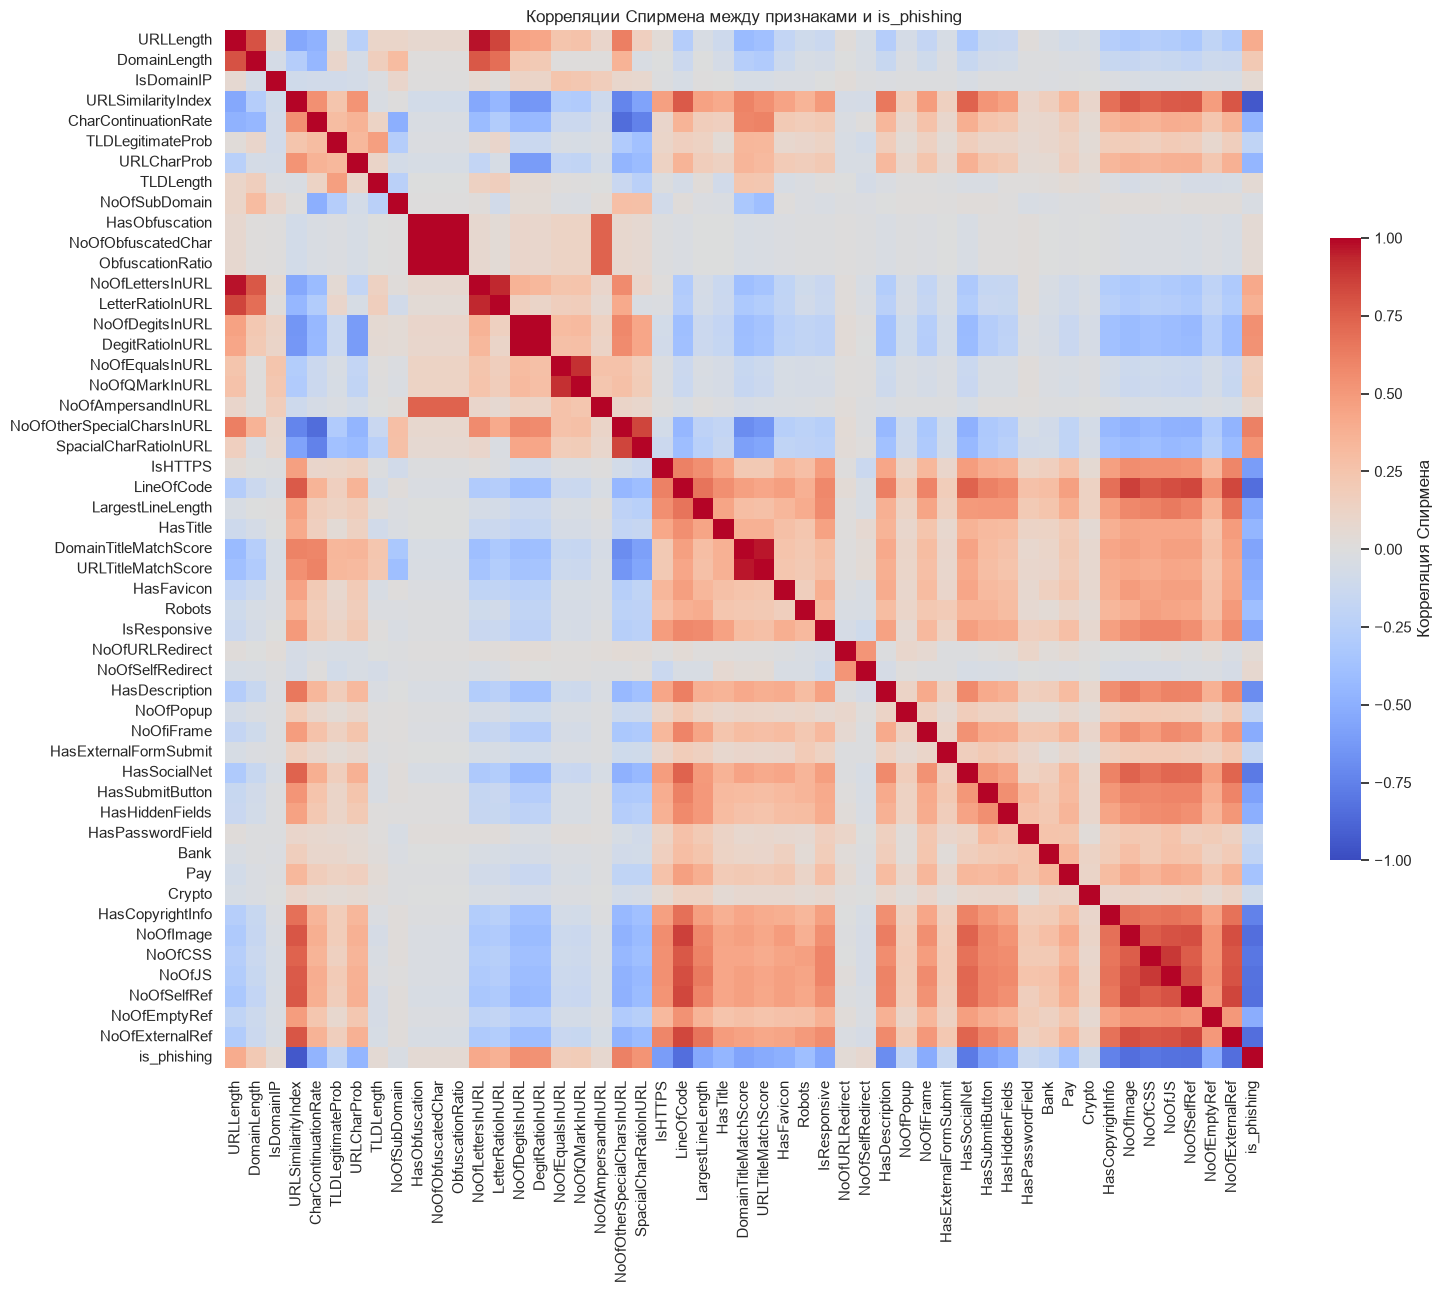

Пар признаков с |rho| > 0.9: 8


|rho|
NoOfObfuscatedChar    ObfuscationRatio    1.000
HasObfuscation        NoOfObfuscatedChar  1.000
                      ObfuscationRatio    1.000
NoOfDegitsInURL       DegitRatioInURL     0.997
URLLength             NoOfLettersInURL    0.972
DomainTitleMatchScore URLTitleMatchScore  0.964
NoOfLettersInURL      LetterRatioInURL    0.931
NoOfEqualsInURL       NoOfQMarkInURL      0.910

In [21]:
# Spearman вместо Пирсона: распределения сильно скошены, а Spearman работает с рангами
corr = df[num_cols + [TARGET]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"shrink": 0.6, "label": "Корреляция Спирмена"}, ax=ax)
ax.set(title="Корреляции Спирмена между признаками и is_phishing")
plt.tight_layout()
plt.show()

upper = corr.drop(index=TARGET, columns=TARGET).abs()
upper = upper.where(np.triu(np.ones(upper.shape, dtype=bool), k=1))
strong_pairs = upper.stack().loc[lambda s: s > 0.9].sort_values(ascending=False)
print(f"Пар признаков с |rho| > 0.9: {len(strong_pairs)}")
display(strong_pairs.to_frame("|rho|"))

На матрице видны два больших блока: **признаки URL** (верхний левый угол) и **признаки HTML-страницы**
(нижний правый, сильно связаны между собой - все они отражают «объём» страницы).

8 пар с |rho| > 0.9 - дублирующие по построению признаки:
1) `HasObfuscation`, `NoOfObfuscatedChar`, `ObfuscationRatio` (1.0) - одна и та же информация, достаточно одного;
2) количество и доля: `NoOfDegitsInURL` / `DegitRatioInURL` (0.997), `NoOfLettersInURL` / `LetterRatioInURL` (0.93);
3) `URLLength` / `NoOfLettersInURL` (0.97) - длина URL в основном складывается из букв;
4) `DomainTitleMatchScore` / `URLTitleMatchScore` (0.96) - у главных страниц URL ≈ домен;
5) `NoOfEqualsInURL` / `NoOfQMarkInURL` (0.91) - параметры запроса `?a=b` появляются вместе.

Для линейных моделей из каждой группы стоит оставить один признак (мультиколлинеарность делает веса неустойчивыми);
деревьям это менее критично, но дубли размывают оценку важности признаков.

### 11.2. Связь признаков с целевой переменной: phik vs Спирмен

Коэффициент phik (рассматривался в курсе) работает с числовыми и категориальными признаками одновременно
и улавливает нелинейные зависимости. Считаем его на стратифицированной подвыборке 20 000 строк и сравниваем с корреляцией Спирмена.

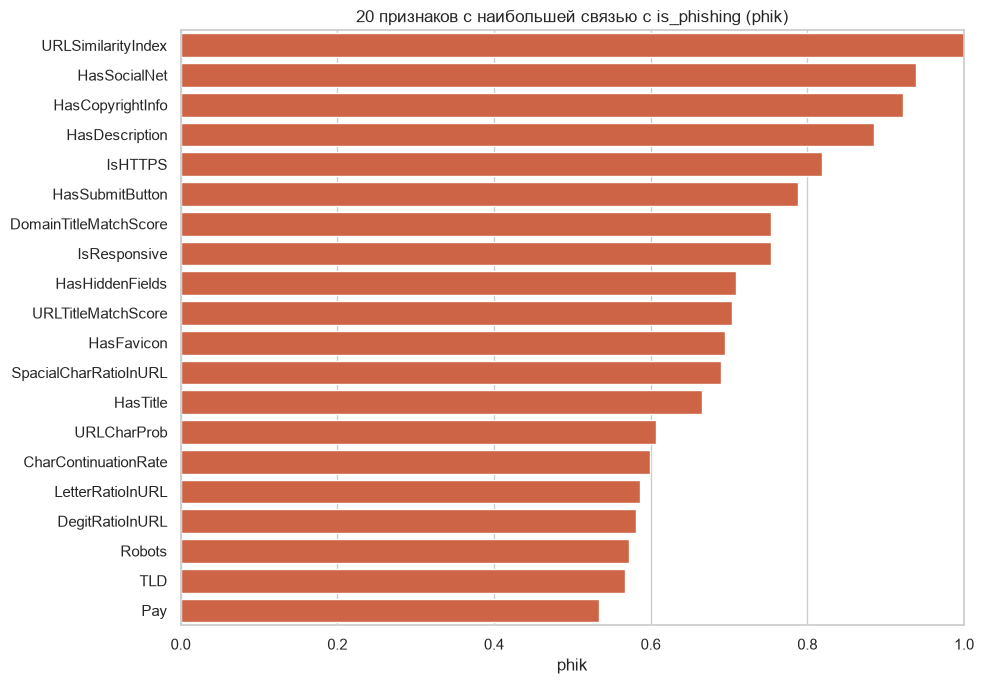

,URLSimilarityIndex,HasSocialNet,HasCopyrightInfo,HasDescription,IsHTTPS,HasSubmitButton,DomainTitleMatchScore,IsResponsive,HasHiddenFields,URLTitleMatchScore,HasFavicon,SpacialCharRatioInURL,HasTitle,URLCharProb,CharContinuationRate,LetterRatioInURL,DegitRatioInURL,Robots,TLD,Pay
phik,1.000,0.938,0.922,0.885,0.819,0.788,0.754,0.753,0.709,0.703,0.695,0.690,0.665,0.607,0.599,0.587,0.582,0.573,0.567,0.534
Spearman,-0.945,-0.784,-0.743,-0.690,-0.609,-0.579,-0.570,-0.549,-0.508,-0.525,-0.494,0.527,-0.460,-0.459,-0.470,0.369,0.536,-0.393,NaN,-0.360


In [22]:
# phik работает со смешанными типами и ловит нелинейные связи, но считается долго -
# берём стратифицированную подвыборку 20 000 строк
sample = df.groupby(TARGET, group_keys=False).sample(frac=20_000 / len(df), random_state=RANDOM_STATE)
phik_cols = num_cols + ["TLD", TARGET]
# TLD с редкими значениями объединяем, иначе phik строит огромную таблицу сопряжённости
sample = sample.assign(TLD=sample["TLD"].where(sample["TLD"].isin(df["TLD"].value_counts().index[:30]), "other"))
phik_target = (
    sample[phik_cols]
    .phik_matrix(interval_cols=cont_cols, verbose=False)[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
)

spearman_target = corr[TARGET].drop(TARGET)
cmp = pd.DataFrame({"phik": phik_target, "Spearman": spearman_target}).sort_values("phik", ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
top = cmp.head(20)
sns.barplot(x=top["phik"], y=top.index, color=PALETTE["Фишинг"], ax=ax)
ax.set(title="20 признаков с наибольшей связью с is_phishing (phik)", xlabel="phik", ylabel="", xlim=(0, 1))
plt.tight_layout()
plt.show()
display(cmp.head(20).T)

1) Максимальная связь у `URLSimilarityIndex` (phik = 1.0) - подтверждение утечки (п. 7.3);
2) Далее идут бинарные признаки «зрелого» сайта: `HasSocialNet` (0.94), `HasCopyrightInfo` (0.92), `HasDescription` (0.89)
   и `IsHTTPS` (0.82) - артефакт отбора;
3) Из «честных» признаков URL высокую связь показывают `SpacialCharRatioInURL` (0.69), `URLCharProb`, `CharContinuationRate`,
   `DegitRatioInURL` (~0.6) и `TLD` (0.57) - на них стоит опираться в модели, устойчивой к смене источника данных;
4) Знак Спирмена показывает направление: чем больше спецсимволов и цифр - тем вероятнее фишинг; чем больше признаков
   «нормального» сайта - тем менее вероятен;
5) `LineOfCode` и другие счётные HTML-признаки (AUC 0.96-0.99 в п. 7.2) не попали в топ-20 phik. Это особенность
   метода: phik по умолчанию разбивает числовой признак на равные по ширине интервалы, и при огромных хвостах почти
   все значения попадают в первый интервал. Вывод - для скошенных признаков phik нужно считать после логарифмирования
   и не полагаться на одну меру связи.

## 12. PCA: насколько классы разделимы

Проецируем данные на две главные компоненты (после `log1p` и стандартизации) на подвыборке 8 000 точек.
Сравниваем проекцию со всеми признаками и без двух утечек (`URLSimilarityIndex`, `IsHTTPS`).

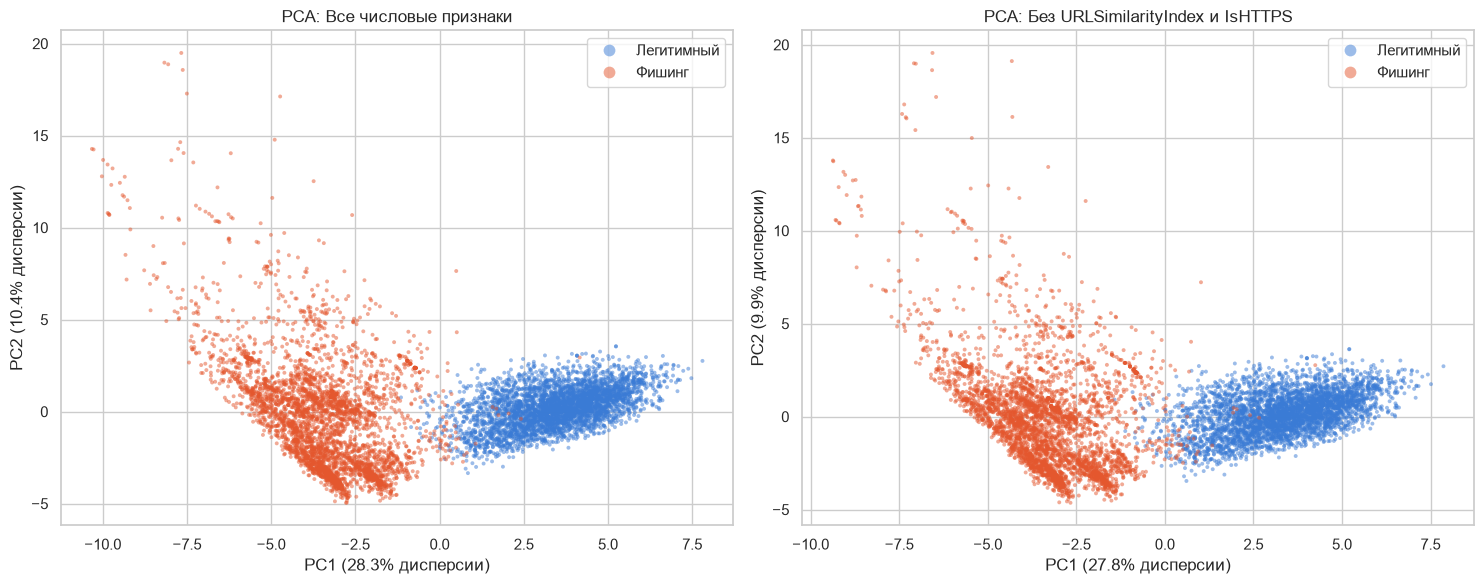

In [23]:
# PCA на логарифмированных и стандартизированных признаках (подвыборка для наглядности).
# Строим два варианта: со всеми признаками и без признаков-утечек (см. раздел 5).
leaky = ["URLSimilarityIndex", "IsHTTPS"]
pca_sample = df.groupby(TARGET, group_keys=False).sample(n=4000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (title, cols) in zip(axes, [("Все числовые признаки", num_cols),
                                    ("Без URLSimilarityIndex и IsHTTPS", [c for c in num_cols if c not in leaky])]):
    X = StandardScaler().fit_transform(np.log1p(pca_sample[cols].clip(lower=0)))
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pc = pca.fit_transform(X)
    sns.scatterplot(x=pc[:, 0], y=pc[:, 1], hue=pca_sample["Класс"].values, hue_order=ORDER,
                    palette=PALETTE, s=8, alpha=0.5, linewidth=0, ax=ax)
    ev = pca.explained_variance_ratio_
    ax.set(title=f"PCA: {title}", xlabel=f"PC1 ({ev[0]:.1%} дисперсии)", ylabel=f"PC2 ({ev[1]:.1%} дисперсии)")
    ax.legend(title="", markerscale=3)
plt.tight_layout()
plt.show()

1) Уже в двух линейных компонентах классы разделяются почти полностью: легитимные сайты - компактное облако справа,
   фишинг - вытянутое облако слева. Первая компонента объясняет ~28% дисперсии и по сути означает «объём страницы»;
2) Удаление `URLSimilarityIndex` и `IsHTTPS` картину почти не меняет: разделимость обеспечивают HTML-признаки,
   то есть эффект «пустых страниц» из п. 8.4;
3) Фишинговое облако гораздо шире: фишинг неоднороден (заглушки, IPFS-страницы, копии банков, длинные URL-редиректы),
   тогда как легитимные объекты однотипны (главные страницы популярных сайтов). Для бинарной модели это не проблема,
   но для анализа ошибок полезно разбить фишинг на подтипы.

Ожидаемо, что любая модель на этих данных покажет качество 99%+. Главный вопрос в этой задаче - не «какая модель лучше», а
«насколько качество переносится на реальный трафик», поэтому эксперименты нужно проводить с разными наборами признаков.

## 13. Итоговые выводы

**Что с данными не так:**
1) **Утечки целевой переменной:** `FILENAME` (префикс и номер файла однозначно задают класс) и `URLSimilarityIndex`
   (= 100 у всех легитимных URL; одно правило даёт accuracy 99.7%);
2) **Артефакты сбора:** все легитимные URL - главные страницы вида `https://www.<домен>` без пути; `IsHTTPS = 1` у всех легитимных;
   новые TLD (`app`, `dev`, `io`) почти полностью фишинговые, потому что легитимные домены взяты из рейтинга старых сайтов;
3) **«Мёртвые» страницы:** 77% фишинговых HTML-страниц - заглушки (< 100 строк, половина без единой ссылки). HTML-признаки
   описывают скорее момент скачивания, чем саму фишинговую страницу; из-за этого признаки `HasPasswordField`, `Bank`, `Pay`
   на всей выборке «перевёрнуты»;
4) **Скрытые пропуски и грязь:** `Title = '0'` вместо пустого заголовка (32 719 строк), ошибки кодировки и `#NAME?` в `Title`;
5) 425 URL повторяются (все - фишинг), противоречивых меток нет; искусственный баланс классов 57/43.

**Предобработка:**
1) Исключить `FILENAME` и `label`; `URLSimilarityIndex` убрать из основной модели (или сравнить модели с ним и без него);
2) Разбивать на train/test со стратификацией по `is_phishing` и группировкой по `URL` (повторы - в одну часть),
   например через `StratifiedGroupKFold`;
3) Счётные признаки - `log1p`, затем стандартизация (для линейных моделей и kNN); выбросы не удалять;
4) Удалить дублирующие признаки: оставить один из группы обфускации, один из пар «количество / доля»,
   один из `DomainTitleMatchScore` / `URLTitleMatchScore`;
5) `TLD` - топ-30 значений + `other` (one-hot) или target encoding по фолдам; `Title = '0'` → пустая строка;
6) Добавить признак «страница-заглушка» (мало строк HTML и нет ссылок).

**План экспериментов:**
1) Baseline - логистическая регрессия, далее - деревья решений / градиентный бустинг;
2) Три набора признаков: (а) все признаки; (б) без утечек; (в) только признаки URL (без HTML и без артефактов формата) -
   наиболее близкий к продакшену сценарий проверки ссылки в письме без скачивания страницы;
3) Метрики - PR-AUC и Recall при FPR ≤ 0.1% (п. 2), отдельно качество на «живых» фишинговых страницах; precision
   пересчитать на реалистичную долю фишинга в потоке;
4) Для проверки переносимости - собрать небольшую выборку реальных легитимных URL с путями (ссылки из корпоративной почты)
   и посмотреть FPR модели на ней.